In [20]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os

# Go one level up from the current working directory
ROOT_DIR = os.path.dirname(os.getcwd())

#Build Path
DATA_DIR = os.path.join(ROOT_DIR, "data", "raw")

# Load datasets
train = pd.read_parquet(os.path.join(DATA_DIR, "train.parquet"))
#test = pd.read_parquet(os.path.join(DATA_DIR, "test.parquet"))

# EDA

## Introduction to the dataset 

In [21]:
train.sample(5)

,status,gender,firstName,level,lastName,userId,ts,auth,page,sessionId,location,itemInSession,userAgent,method,length,song,artist,time,registration
20481834,200,F,Mya,paid,Clayton,1425375,1539903498000,Logged In,NextSong,11655,"Toledo, OH",7,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_4...",PUT,217.28608,Patterns,EMF,2018-10-18 22:58:18,2018-09-28 17:05:40
6163435,200,F,Jada,paid,Bryant,1291962,1539948801000,Logged In,NextSong,96425,"San Francisco-Oakland-Hayward, CA",376,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_4...",PUT,271.51628,Guantanamera,Wyclef Jean featuring Refugee Allstars,2018-10-19 11:33:21,2018-09-21 10:38:45
5197543,200,F,Ava,paid,Simpson,1181953,1539730990000,Logged In,NextSong,78992,"New York-Newark-Jersey City, NY-NJ-PA",87,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_4...",PUT,201.79546,Revelry,Kings Of Leon,2018-10-16 23:03:10,2018-07-09 00:30:58
1117976,200,F,Aileen,paid,Mckinney,1628350,1538649378000,Logged In,NextSong,35371,"Los Angeles-Long Beach-Anaheim, CA",258,"""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK...",PUT,207.07220,Boten Anna [Radio edit],Basshunter,2018-10-04 10:36:18,2018-07-13 16:18:31
6871322,200,M,Elijah,free,Hernandez,1523961,1540169983000,Logged In,NextSong,103015,"Dallas-Fort Worth-Arlington, TX",43,"""Mozilla/5.0 (Windows NT 6.3; WOW64) AppleWebK...",PUT,290.11546,Burden In My Hand,Soundgarden,2018-10-22 00:59:43,2018-08-25 18:15:12


In [22]:
train.shape

# Dataset is composed of 17,499,636 observations of 19 features

(17499636, 19)

In [23]:
train.describe()

,status,ts,sessionId,itemInSession,length,time,registration
count,1.749964e+07,1.749964e+07,1.749964e+07,1.749964e+07,1.429143e+07,17499636,17499636
mean,2.091387e+02,1.540428e+12,8.480294e+04,1.055937e+02,2.487135e+02,2018-10-25 00:47:01.161927,2018-08-25 04:40:21.543066
min,2.000000e+02,1.538352e+12,1.000000e+00,0.000000e+00,5.220000e-01,2018-10-01 00:00:01,2017-10-14 22:05:25
25%,2.000000e+02,1.539340e+12,2.515900e+04,2.600000e+01,1.998885e+02,2018-10-12 10:33:57.750000,2018-08-10 21:14:59
50%,2.000000e+02,1.540397e+12,7.903800e+04,6.600000e+01,2.340828e+02,2018-10-24 15:58:54,2018-09-05 18:35:50
75%,2.000000e+02,1.541500e+12,1.383680e+05,1.440000e+02,2.768714e+02,2018-11-06 10:25:35,2018-09-20 17:24:57
max,4.040000e+02,1.542672e+12,2.070030e+05,1.426000e+03,3.024666e+03,2018-11-20 00:00:00,2018-11-19 23:34:34
std,3.023050e+01,1.233485e+09,6.141427e+04,1.168854e+02,9.722845e+01,NaN,NaN


In [24]:
# Checking for missing values by columns
train.isna().sum()

# We observe that all missing values are located either length, song or artist with total 3,208,203 missing values


status                 0
gender                 0
firstName              0
level                  0
lastName               0
userId                 0
ts                     0
auth                   0
page                   0
sessionId              0
location               0
itemInSession          0
userAgent              0
method                 0
length           3208203
song             3208203
artist           3208203
time                   0
registration           0
dtype: int64

In [25]:
train[train["song"].isna()].sample(3)
# These 3,208,203 missing values correspond to all the logs where page wasn't related to listening music
# No need to drop them !

,status,gender,firstName,level,lastName,userId,ts,auth,page,sessionId,location,itemInSession,userAgent,method,length,song,artist,time,registration
6735165,307,M,Braiden,paid,Reid,1581951,1540118466000,Logged In,Thumbs Down,104836,"Santa Maria-Santa Barbara, CA",169,Mozilla/5.0 (Windows NT 6.1; WOW64; rv:31.0) G...,PUT,NaN,None,None,2018-10-21 10:41:06,2018-06-16 10:53:48
2385003,200,M,Brayden,free,Hernandez,1617871,1539021692000,Logged In,Add to Playlist,41745,"New York-Newark-Jersey City, NY-NJ-PA",59,Mozilla/5.0 (X11; Ubuntu; Linux i686; rv:31.0)...,PUT,NaN,None,None,2018-10-08 18:01:32,2018-09-14 17:38:10
6604544,307,M,Kristopher,paid,Thompson,1993527,1540062488000,Logged In,Thumbs Up,102340,"Greensboro-High Point, NC",39,"""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK...",PUT,NaN,None,None,2018-10-20 19:08:08,2018-09-27 14:25:00


In [26]:
# Users are identified by their UserID, one UserID usually has multiple logs
print("Number of unique users:",f"{train['userId'].nunique():,}")

# Example : sample of the 10 first logs of user 1488695
train[train['userId']=='1488695'].sort_values(by='time').sample(10)

Number of unique users: 19,140


,status,gender,firstName,level,lastName,userId,ts,auth,page,sessionId,location,itemInSession,userAgent,method,length,song,artist,time,registration
13735703,200,M,Andrey,paid,Hill,1488695,1541921778000,Logged In,NextSong,179234,"McAllen-Edinburg-Mission, TX",158,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,246.38649,Forever & Always,Taylor Swift,2018-11-11 07:36:18,2018-08-15 06:04:59
3085133,200,M,Andrey,paid,Hill,1488695,1539182581000,Logged In,NextSong,48632,"McAllen-Edinburg-Mission, TX",264,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,225.22730,Back To Life (However Do You Want Me) (2003 Di...,Soul II Soul Featuring Caron Wheeler,2018-10-10 14:43:01,2018-08-15 06:04:59
12143983,200,M,Andrey,free,Hill,1488695,1541512607000,Logged In,NextSong,161650,"McAllen-Edinburg-Mission, TX",33,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,211.17342,Connie & Buster,The Nashville Bluegrass Band,2018-11-06 13:56:47,2018-08-15 06:04:59
14845196,200,M,Andrey,paid,Hill,1488695,1542212147000,Logged In,NextSong,190642,"McAllen-Edinburg-Mission, TX",10,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,278.69995,Lesson Learned,Ray LaMontagne,2018-11-14 16:15:47,2018-08-15 06:04:59
13854321,200,M,Andrey,paid,Hill,1488695,1541967998000,Logged In,NextSong,179234,"McAllen-Edinburg-Mission, TX",392,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,162.87302,Boys Will Be Boys,The Ordinary Boys,2018-11-11 20:26:38,2018-08-15 06:04:59
3307340,200,M,Andrey,paid,Hill,1488695,1539229909000,Logged In,NextSong,66477,"McAllen-Edinburg-Mission, TX",85,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,192.28689,Hold Me,Billy Childish & Holly Golightly,2018-10-11 03:51:49,2018-08-15 06:04:59
3669524,200,M,Andrey,paid,Hill,1488695,1539312333000,Logged In,NextSong,72187,"McAllen-Edinburg-Mission, TX",23,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,224.70485,IMNOTYOURBOYFRIENDBABY (Amended Album Version),3OH!3,2018-10-12 02:45:33,2018-08-15 06:04:59
12762556,200,M,Andrey,free,Hill,1488695,1541654950000,Logged In,NextSong,163933,"McAllen-Edinburg-Mission, TX",21,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,225.82812,Ya Nada Queda,Kudai,2018-11-08 05:29:10,2018-08-15 06:04:59
13851960,200,M,Andrey,paid,Hill,1488695,1541967156000,Logged In,NextSong,179234,"McAllen-Edinburg-Mission, TX",387,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,271.07220,The Perfect Space,The Avett Brothers,2018-11-11 20:12:36,2018-08-15 06:04:59
10569072,200,M,Andrey,free,Hill,1488695,1541073685000,Logged In,Home,146526,"McAllen-Edinburg-Mission, TX",43,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",GET,NaN,None,None,2018-11-01 12:01:25,2018-08-15 06:04:59


In [27]:
# We identify the target variable "Cancellation Confirmation" & "Cancel"

train["page"].value_counts()

page
NextSong                     14291433
Thumbs Up                      789391
Home                           645259
Add to Playlist                409606
Roll Advert                    284837
Add Friend                     262147
Logout                         204700
Thumbs Down                    164964
Downgrade                      124248
Settings                       101191
Help                            89035
Upgrade                         37696
About                           33117
Save Settings                   20370
Error                           17294
Submit Upgrade                  11381
Submit Downgrade                 4425
Cancellation Confirmation        4271
Cancel                           4271
Name: count, dtype: int64

In [ ]:
# "Auth" also seems to be a proxy for Churn, learning on this variable could be detrimental
train["auth"].value_counts()

auth
Logged In    17495365
Cancelled        4271
Name: count, dtype: int64

In [28]:
# Computing the number of users having only used the free version, only the paid version, and the free + paid version

user_types = train.groupby('userId')['level'].agg(
    lambda x: set(x.dropna())
)

# User classification
print(f"Free subscription only: {user_types.apply(lambda x: x == {'free'}).sum():,}")
print(f"Paid subscription only: {user_types.apply(lambda x: x == {'paid'}).sum():,}")
print(f"Both: {user_types.apply(lambda x: x == {'free', 'paid'}).sum():,}")

# the numbers below correctly add up to retrieve the number of unique users : 19,140

Free subscription only: 5,963
Paid subscription only: 3,158
Both: 10,019


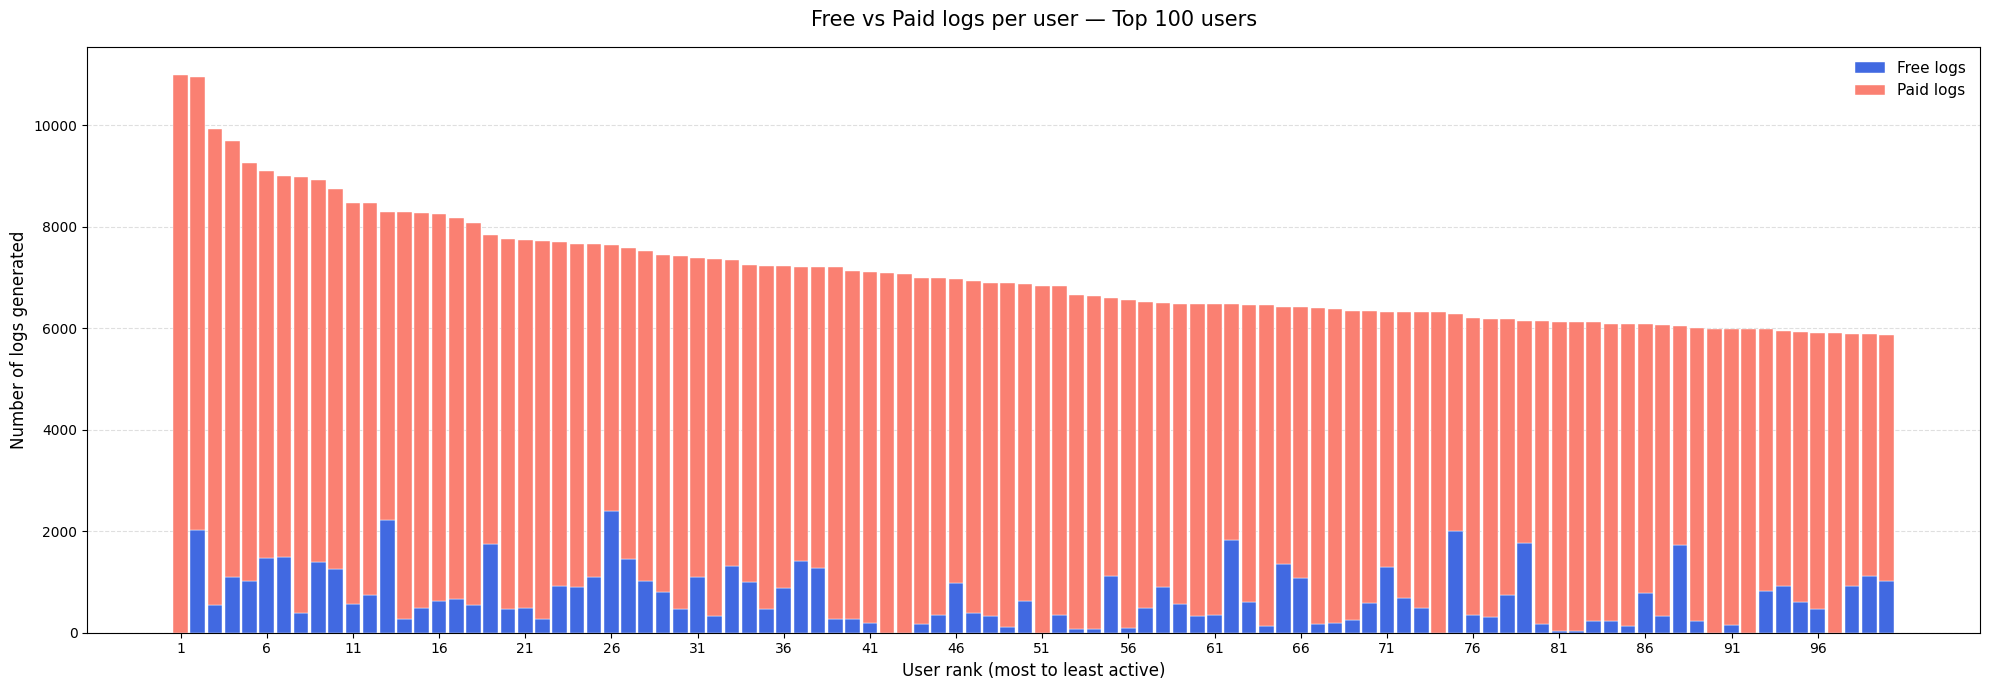

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Count logs per user and subscription type
df_users = (
    train.groupby(['userId', 'level'])
    .size()
    .unstack(fill_value=0)
)

# Rank users by total logs
df_users['totalLogs'] = df_users['free'] + df_users['paid']
df_users = df_users.sort_values('totalLogs', ascending=False)

# Keep top 100 users
df_plot = df_users.head(100)

# Plot
fig, ax = plt.subplots(figsize=(20, 7))

x = np.arange(1, len(df_plot) + 1)

ax.bar(x, df_plot['free'], width=0.85, color='royalblue',
       label='Free logs', edgecolor='white', linewidth=0.3)

ax.bar(x, df_plot['paid'], width=0.85, bottom=df_plot['free'],
       color='salmon', label='Paid logs',
       edgecolor='white', linewidth=0.3)

ax.set_xlabel('User rank (most to least active)', fontsize=12)
ax.set_ylabel('Number of logs generated', fontsize=12)
ax.set_title('Free vs Paid logs per user — Top 100 users',
             fontsize=15, pad=15)

ax.set_xticks(np.arange(1, 101, 5))
ax.tick_params(axis='both', labelsize=10)

ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

ax.legend(fontsize=11, frameon=False)

plt.tight_layout()
plt.show()

In [30]:
# We see that users switching from free to paid subscription substantially increase the use of the streaming service
# Churners could surepresented be among the users that did not decide to switch to paid subscription
# or downgraded from paid to free program

## Defining Churn target 

In [31]:
# Isolating the target variable in Churn (boolean True or False)

train["Churn"] = (train["page"]=="Cancellation Confirmation")

In [32]:
print("Number of Churners:",f"{train['Churn'].sum():,}")
print("Number of Non-Churners",f"{(train['userId'].nunique()) - (train['Churn'].sum()):,}")
print("Number of logs not related to Churning", f"{train.shape[0]-(train['Churn'].sum()):,}")

# The number of users churning is low compared to the number of users who do not (1:3) and
# even lower when considering the number of logs concerning the cancellation (4k vs 17,5 M).
# This hints a possible class imbalance when it will come to predictions (more likely to predict non churners (0))

# Hence the need to use the balanced accuracy, as demanded by the subject : the balanced accuracy gives equal importance to
# the number of correct predictions of 0 and 1. This is relevant as in this case, predicting mostly 0 could yield a very high
# accuracy as most client do not resign their subscription but it is clear that the company is economically much more interested
# to accurately predict the potential churners to try to keep them in !

Number of Churners: 4,271
Number of Non-Churners 14,869
Number of logs not related to Churning 17,495,365


In [33]:
train["page"].value_counts()

page
NextSong                     14291433
Thumbs Up                      789391
Home                           645259
Add to Playlist                409606
Roll Advert                    284837
Add Friend                     262147
Logout                         204700
Thumbs Down                    164964
Downgrade                      124248
Settings                       101191
Help                            89035
Upgrade                         37696
About                           33117
Save Settings                   20370
Error                           17294
Submit Upgrade                  11381
Submit Downgrade                 4425
Cancellation Confirmation        4271
Cancel                           4271
Name: count, dtype: int64

In [34]:
# Let's redefine Churn more granularly

train.drop(columns="Churn")

# Let's make the distinction between churning event and downgrade event (observation level)
# and the churn and downgrade, marking all user's logs as of a churner/ downgrader (userID level)

# 1. Create binary event indicators
train['churn_event'] = (
    train['page'] == 'Cancellation Confirmation'
)

train['downgrade_event'] = (
    train['page'] == 'Submit Downgrade'
)

# 2. Propagate events to all observations of each user
train['churn'] = train.groupby('userId')['churn_event'].transform('max')

train['downgrade'] = train.groupby('userId')['downgrade_event'].transform('max')

train.head()

,status,gender,firstName,level,lastName,userId,ts,auth,page,sessionId,...,length,song,artist,time,registration,Churn,churn_event,downgrade_event,churn,downgrade
0,200,M,Shlok,paid,Johnson,1749042,1538352001000,Logged In,NextSong,22683,...,524.32934,Ich mache einen Spiegel - Dream Part 4,Popol Vuh,2018-10-01 00:00:01,2018-08-08 13:22:21,False,False,False,True,False
992,200,M,Shlok,paid,Johnson,1749042,1538352525000,Logged In,NextSong,22683,...,178.02404,Monster (Album Version),Skillet,2018-10-01 00:08:45,2018-08-08 13:22:21,False,False,False,True,False
1360,200,M,Shlok,paid,Johnson,1749042,1538352703000,Logged In,NextSong,22683,...,232.61995,Seven Nation Army,The White Stripes,2018-10-01 00:11:43,2018-08-08 13:22:21,False,False,False,True,False
1825,200,M,Shlok,paid,Johnson,1749042,1538352935000,Logged In,NextSong,22683,...,265.50812,Under The Bridge (Album Version),Red Hot Chili Peppers,2018-10-01 00:15:35,2018-08-08 13:22:21,False,False,False,True,False
2366,200,M,Shlok,paid,Johnson,1749042,1538353200000,Logged In,NextSong,22683,...,471.69261,Circlesong 6,Bobby McFerrin,2018-10-01 00:20:00,2018-08-08 13:22:21,False,False,False,True,False


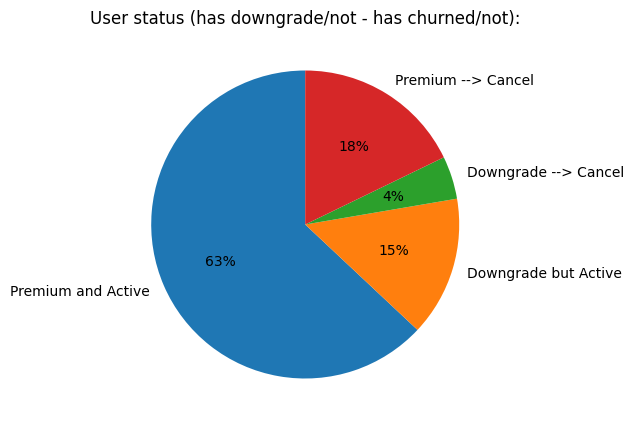

{'Premium and Active': np.int64(12059), 'Downgrade but Active': np.int64(2810), 'Downgrade --> Cancel': np.int64(861), 'Premium --> Cancel': np.int64(3410)}


In [ ]:
import matplotlib.pyplot as plt

# One row per user
users = train.drop_duplicates('userId')

subjects = [
    'Premium and Active',
    'Downgrade but Active',
    'Downgrade --> Cancel',
    'Premium --> Cancel'
]

data = [
    ((users['downgrade'] == 0) & (users['churn'] == 0)).sum(),
    ((users['downgrade'] == 1) & (users['churn'] == 0)).sum(),
    ((users['downgrade'] == 1) & (users['churn'] == 1)).sum(),
    ((users['downgrade'] == 0) & (users['churn'] == 1)).sum()
]

fig, ax = plt.subplots(figsize=(5, 5))

ax.pie(
    data,
    labels=subjects,
    autopct='%1.0f%%',
    startangle=90
)

ax.set_title('User status (has downgrade/not - has churned/not):')

plt.show()

print(dict(zip(subjects, data)))

# This pie chart suggests that quite a large part of the users downgrading their subscription
# still decide to keep their account and use the platform

# Be careful, this pie chart does not include the Free users Active, only the former Premium Active (15%)